In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image


In [24]:
sns.set_theme()

In [25]:
experiment_folder = "enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3"

# Custom anomaly vs. normal box experiment

In [26]:
results_df = pd.read_csv(f"experiments/{experiment_folder}/l2_distance_anomaly_vs_normal_box_validation_multiple_seeds.csv")

In [27]:
results_df = results_df[["image_name", "l2_distance_anomaly_box", "l2_distance_normal_box", "box_size"]]


In [28]:
results_df

,image_name,l2_distance_anomaly_box,l2_distance_normal_box,box_size
0,00124_60,5.550597,2.135955,"(96, 96)"
1,00124_70,5.933988,2.081113,"(96, 96)"
2,00124_80,5.576666,1.990012,"(96, 96)"
3,00124_90,3.259935,2.154751,"(96, 96)"
4,00134_60,3.168956,1.813586,"(96, 96)"
...,...,...,...,...
655,01597_90,4.657138,1.459719,"(96, 80)"
656,01646_60,2.321241,1.935580,"(96, 80)"
657,01646_70,1.141485,2.050866,"(96, 80)"
658,01646_80,1.611030,1.369975,"(96, 80)"


In [29]:
results_df["l2_anomaly - l2_normal"] = results_df["l2_distance_anomaly_box"] - results_df["l2_distance_normal_box"]


In [30]:
results_df.sort_values(by="l2_anomaly - l2_normal", ascending=False)

,image_name,l2_distance_anomaly_box,l2_distance_normal_box,box_size,l2_anomaly - l2_normal
515,01388_90,9.915632,3.361125,"(80, 96)",6.554507
602,01388_80,8.687897,2.787585,"(80, 96)",5.900312
471,01388_90,9.336968,3.443378,"(96, 80)",5.893590
603,01388_90,9.192269,3.363693,"(80, 96)",5.828576
514,01388_80,8.514136,2.687680,"(80, 96)",5.826456
...,...,...,...,...,...
569,01646_70,1.197752,2.672792,"(96, 80)",-1.475040
421,01180_70,1.221933,2.741782,"(112, 80)",-1.519849
437,01646_70,1.940083,3.573280,"(112, 80)",-1.633197
300,01597_60,2.474637,5.160224,"(96, 80)",-2.685588


In [31]:
results_df[results_df['l2_anomaly - l2_normal'] > 0]

,image_name,l2_distance_anomaly_box,l2_distance_normal_box,box_size,l2_anomaly - l2_normal
0,00124_60,5.550597,2.135955,"(96, 96)",3.414641
1,00124_70,5.933988,2.081113,"(96, 96)",3.852875
2,00124_80,5.576666,1.990012,"(96, 96)",3.586654
3,00124_90,3.259935,2.154751,"(96, 96)",1.105184
4,00134_60,3.168956,1.813586,"(96, 96)",1.355370
...,...,...,...,...,...
654,01597_80,4.438148,1.472549,"(96, 80)",2.965599
655,01597_90,4.657138,1.459719,"(96, 80)",3.197418
656,01646_60,2.321241,1.935580,"(96, 80)",0.385660
658,01646_80,1.611030,1.369975,"(96, 80)",0.241055



Image: 


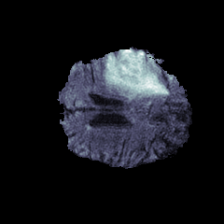


Segmentation: 


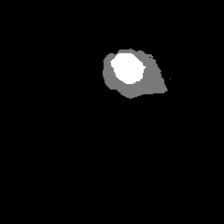


Anomaly box: 


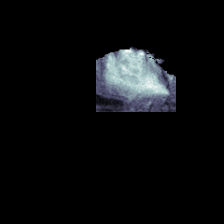


Normal box: 


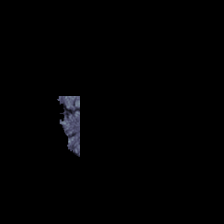


Context: 


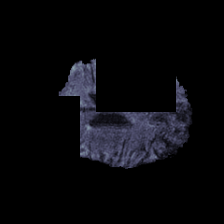

In [32]:
# Example of selected boxes

image_name = "01597_90"

print("\nImage: ")
display(Image.open(f"experiments/{experiment_folder}/custom_anomaly_normal_boxes/{image_name}_image.png"))
print("\nSegmentation: ")
display(Image.open(f"experiments/{experiment_folder}/custom_anomaly_normal_boxes/{image_name}_segmentation.png"))
print("\nAnomaly box: ")
display(Image.open(f"experiments/{experiment_folder}/custom_anomaly_normal_boxes/{image_name}_anomaly_pixels_mask_image.png"))
print("\nNormal box: ")
display(Image.open(f"experiments/{experiment_folder}/custom_anomaly_normal_boxes/{image_name}_normal_pixels_mask_image.png"))
print("\nContext: ")
display(Image.open(f"experiments/{experiment_folder}/custom_anomaly_normal_boxes/{image_name}_context_image.png"))


In [33]:
results_df["l2_distance_anomaly_box"].mean()

3.710647747552756

In [34]:
results_df["l2_distance_normal_box"].mean()

1.944280856757453

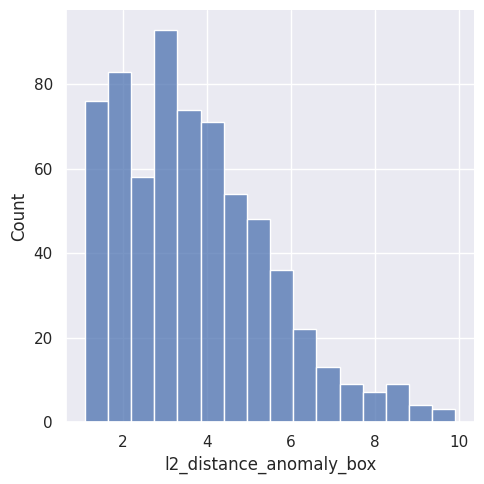

In [35]:
sns.displot(data=results_df, x="l2_distance_anomaly_box", kind="hist")

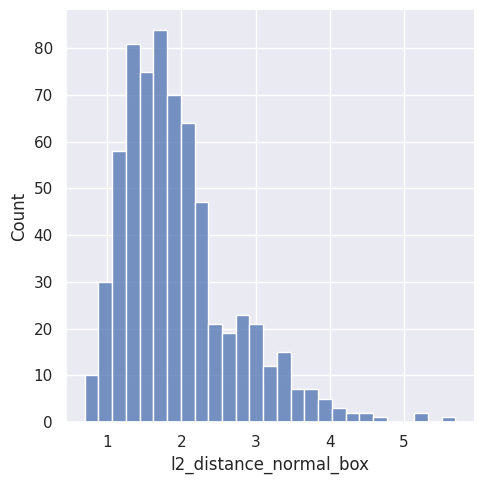

In [36]:
sns.displot(data=results_df, x="l2_distance_normal_box", kind="hist")

In [37]:
l2_distances = results_df["l2_distance_anomaly_box"].to_list() + results_df["l2_distance_normal_box"].to_list()
box_types = ["anomaly"] * len(results_df["l2_distance_anomaly_box"].to_list()) + ["normal"] * len(results_df["l2_distance_normal_box"].to_list())

differences_plot_df = pd.DataFrame({"l2_distance": l2_distances, "box_type": box_types})


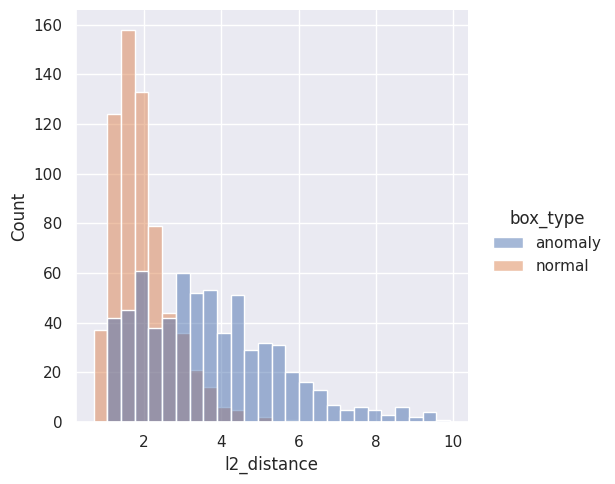

In [38]:
sns.displot(differences_plot_df, x="l2_distance", hue="box_type", kind="hist")

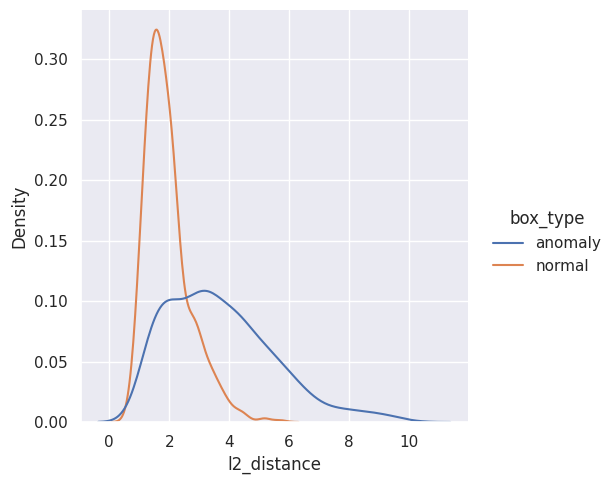

In [39]:
sns.displot(differences_plot_df, x="l2_distance", hue="box_type", kind="kde")

# Random boxes experiment

In [40]:
results_random_box_df = pd.read_csv(f"experiments/{experiment_folder}/l2_distance_random_box_multiple_seeds.csv")


In [41]:
results_random_box_df

,image_name,label,l2_distance,box_size,seed
0,00124_60,1,4.072405,"(96, 96)",0
1,00124_70,1,3.403638,"(96, 96)",0
2,00124_80,1,2.928276,"(96, 96)",0
3,00124_90,1,2.056443,"(96, 96)",0
4,00134_60,1,2.738162,"(96, 96)",0
...,...,...,...,...,...
2485,01505_60,0,1.218816,"(80, 96)",29
2486,01514_99,0,1.199514,"(80, 96)",29
2487,01555_60,0,1.335940,"(80, 96)",29
2488,01616_99,0,1.266531,"(80, 96)",29


In [42]:
results_random_box_df[(results_random_box_df["image_name"] == "00134_60") & (results_random_box_df["seed"].isin([10, 11, 12, 13]))]

,image_name,label,l2_distance,box_size,seed
834,00134_60,1,1.724984,"(96, 80)",10
917,00134_60,1,2.904608,"(80, 96)",11
1000,00134_60,1,3.167687,"(96, 80)",12
1083,00134_60,1,3.460510,"(80, 96)",13



Image: 


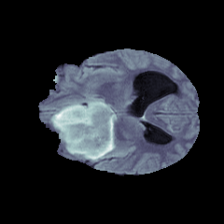


Random box: 


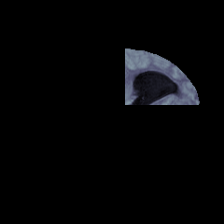


Context: 


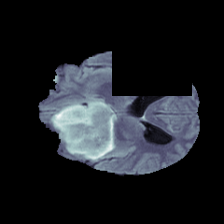

In [43]:
# Example of sampled boxes

image_name = "00134_60"
box_id = 10

print("\nImage: ")
display(Image.open(f"experiments/{experiment_folder}/random_boxes/{image_name}_image.png"))
print("\nRandom box: ")
display(Image.open(f"experiments/{experiment_folder}/random_boxes/{image_name}_random_pixels_mask_image_{box_id}.png"))
print("\nContext: ")
display(Image.open(f"experiments/{experiment_folder}/random_boxes/{image_name}_context_image_{box_id}.png"))


## Using 30 randomly sampled boxes

Anomaly images: mean L2 distance:  2.6243832002986562
Normal images: mean L2 distance:  1.5335768496378874


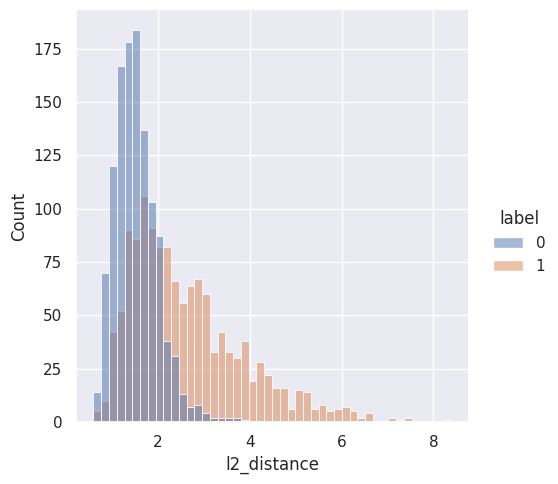

In [44]:
print("Anomaly images: mean L2 distance: ", results_random_box_df[results_random_box_df["label"] == 1]["l2_distance"].mean())
print("Normal images: mean L2 distance: ", results_random_box_df[results_random_box_df["label"] == 0]["l2_distance"].mean())

sns.set_theme()
sns.displot(results_random_box_df, x="l2_distance", hue="label", kind="hist")

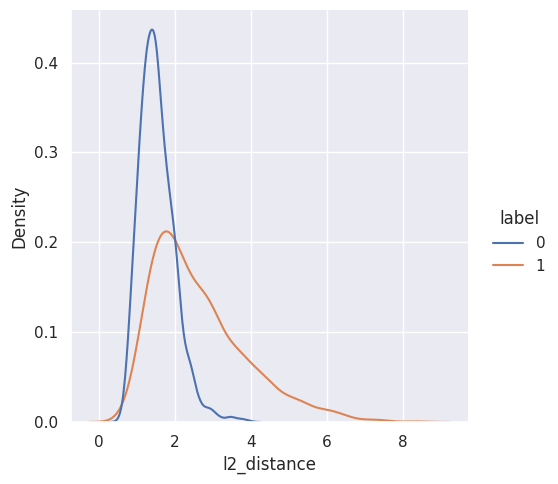

In [45]:
sns.displot(results_random_box_df, x="l2_distance", hue="label", kind="kde")

In [46]:
normal_image_mean_l2_distances_per_num_random_boxes = {}
anomaly_image_mean_l2_distances_per_num_random_boxes = {}

box_numbers = sorted(set(results_random_box_df["seed"].to_list()))

for box_num in box_numbers:
    normal_df = results_random_box_df[
        (results_random_box_df["label"] == 0) & 
        (results_random_box_df["seed"] <= box_num)]
    normal_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = normal_df["l2_distance"].mean()
    
    anomaly_df = results_random_box_df[
        (results_random_box_df["label"] == 1) & 
        (results_random_box_df["seed"] <= box_num)]
    anomaly_image_mean_l2_distances_per_num_random_boxes[box_num + 1] = anomaly_df["l2_distance"].mean()


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Normal images')]

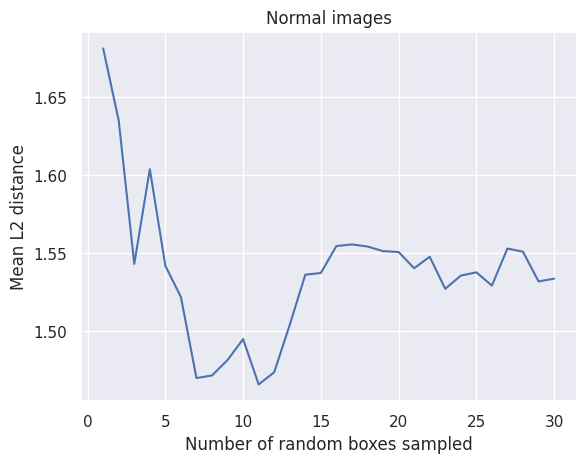

In [47]:
ax = sns.lineplot(x=list(normal_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(normal_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Normal images")


[Text(0.5, 0, 'Number of random boxes sampled'),
 Text(0, 0.5, 'Mean L2 distance'),
 Text(0.5, 1.0, 'Anomaly images')]

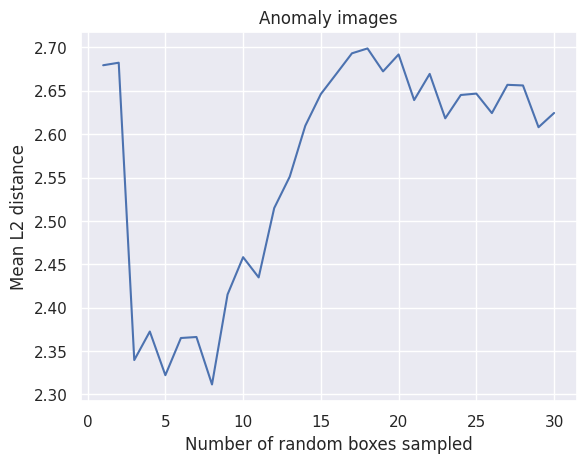

In [48]:
ax = sns.lineplot(x=list(anomaly_image_mean_l2_distances_per_num_random_boxes.keys()), 
            y=list(anomaly_image_mean_l2_distances_per_num_random_boxes.values()))
ax.set(xlabel='Number of random boxes sampled', ylabel='Mean L2 distance', title="Anomaly images")

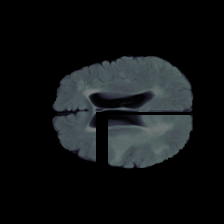

In [54]:
from PIL import Image

context = Image.open("experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vith14_ijepa_target_vits16_dinov3/random_boxes/01646_90_context_image_29.png").convert("RGBA")
box = Image.open("experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vith14_ijepa_target_vits16_dinov3/random_boxes/01646_90_random_pixels_mask_image_29.png").convert("RGBA")
image = Image.open("experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vith14_ijepa_target_vits16_dinov3/random_boxes/01646_90_image.png").convert("RGBA")

Image.blend(context, box, alpha=0.5)


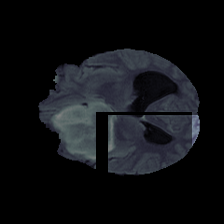

In [59]:
from PIL import Image

context = Image.open("experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3/random_boxes/00134_60_context_image_29.png").convert("RGBA")
box = Image.open("experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3/random_boxes/00134_60_random_pixels_mask_image_29.png").convert("RGBA")
image = Image.open("experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vitg16_ijepa_target_vits16_dinov3/random_boxes/00134_60_image.png").convert("RGBA")

Image.blend(context, box, alpha=0.5)


In [50]:
context = Image.open("/home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vith14_ijepa_target_vits16_dinov3/custom_anomaly_normal_boxes/00124_60_context_image.png")
normal = Image.open("/home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vith14_ijepa_target_vits16_dinov3/custom_anomaly_normal_boxes/00124_60_normal_pixels_mask_image.png")
anomaly = Image.open("/home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vith14_ijepa_target_vits16_dinov3/custom_anomaly_normal_boxes/00124_60_anomaly_pixels_mask_image.png")
image = Image.open("/home/vhondru/istoian/ijepa-anomaly-detection/experiments_BraTS2021_slice/enc_vits16_dinov3_pred_vith14_ijepa_target_vits16_dinov3/custom_anomaly_normal_boxes/00124_60_image.png")

blend1 = Image.blend(context, normal, alpha=0.5)
blend2 = Image.blend(blend1, anomaly, alpha=0.5)

# blend = Image.blend(blend1, anomaly, alpha=0.5)

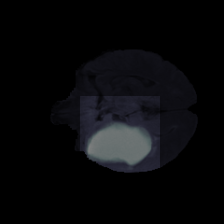

In [51]:
blend2

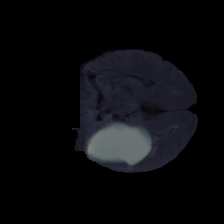

In [39]:
blend2